In [50]:
import pandas as pd
from matplotlib import pyplot as plt

In [51]:
df = pd.read_excel('income.xlsx')
df.head()

,Name,Age,Income($)
0,Rob,27,70000
1,Michael,29,90000
2,Mohan,29,61000
3,Ismail,28,60000
4,Kory,42,150000


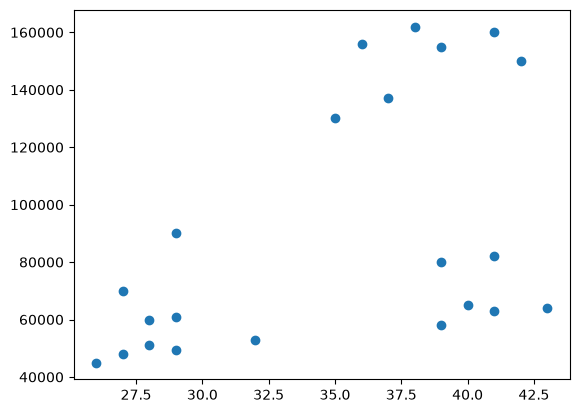

In [52]:
plt.scatter(df['Age'], df['Income($)'])
plt.show()

In [53]:
from sklearn.cluster import KMeans

km = KMeans(n_clusters=3, n_init='auto',random_state=42)
km.fit(df[['Age','Income($)']])
km.labels_

c:\Users\PRATHAMESH\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


array([1, 2, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 1],
      dtype=int32)

In [54]:
df.shape

(22, 3)

In [55]:
df['cluster'] = km.labels_
df.head()

,Name,Age,Income($),cluster
0,Rob,27,70000,1
1,Michael,29,90000,2
2,Mohan,29,61000,1
3,Ismail,28,60000,1
4,Kory,42,150000,0


In [56]:
import seaborn as sns

<Axes: xlabel='Age', ylabel='Income($)'>

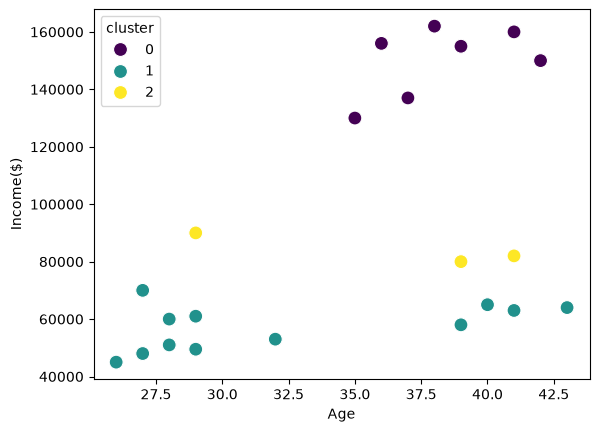

In [57]:
sns.scatterplot(df, x='Age', y='Income($)', palette='viridis', s=100, hue='cluster')

clusters are not formed properly. it can be due to Age and income columns being on a different scale. we can try scalling them 

# Min Max Scaling


In [58]:
from sklearn.preprocessing import MinMaxScaler

In [59]:
scaler = MinMaxScaler()

In [60]:
df_scaled = pd.DataFrame(columns=['Age','Income($)'])

In [61]:
df_scaled[['Age','Income($)']]= scaler.fit_transform(df[['Age','Income($)']])
km.fit(df_scaled[['Age','Income($)']])
df_scaled['cluster'] = km.labels_
df_scaled.head()

c:\Users\PRATHAMESH\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


,Age,Income($),cluster
0,0.058824,0.213675,1
1,0.176471,0.384615,1
2,0.176471,0.136752,1
3,0.117647,0.128205,1
4,0.941176,0.897436,0


<Axes: xlabel='Age', ylabel='Income($)'>

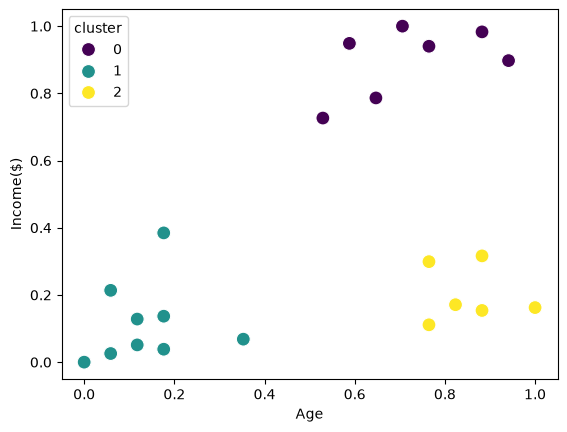

In [62]:
sns.scatterplot(df_scaled, x='Age', y='Income($)', palette='viridis', s=100, hue='cluster')

In [63]:
centroids = km.cluster_centers_
centroids

array([[0.72268908, 0.8974359 ],
       [0.1372549 , 0.11633428],
       [0.85294118, 0.2022792 ]])

<Axes: xlabel='Age', ylabel='Income($)'>

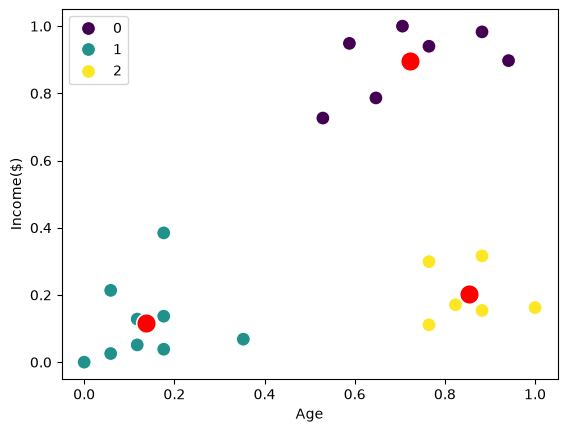

In [64]:
sns.scatterplot(df_scaled, x='Age', y='Income($)', palette='viridis', s=100, hue='cluster')
sns.scatterplot(x=centroids[:,0], y=centroids[:,1],s=200, color='red',markers='*')

In [65]:
new_data = pd.DataFrame({
    'Age':[25,42,55],
    'Income($)':[35000,90000,150000]
})

In [66]:
new_data_scaled = scaler.transform(new_data)

In [67]:
predictions = km.predict(new_data_scaled)
print(predictions)

[1 2 0]


c:\Users\PRATHAMESH\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but KMeans was fitted with feature names
  warnings.warn(


# Elbow Method to Determine Optimal Number Of Clusters

In [68]:
sse = []

k_rng = range(1,10)

for k in k_rng:
    km = KMeans(n_clusters=k, n_init='auto')
    km.fit(df_scaled[['Age', 'Income($)']])
    sse.append(km.inertia_)
sse    

c:\Users\PRATHAMESH\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\PRATHAMESH\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\PRATHAMESH\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\PRATHAMESH\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a m

[5.434011511988179,
 2.3456144914725936,
 0.4750783498553096,
 0.3491047094419566,
 0.286071710668944,
 0.21055478995472496,
 0.19580866480912326,
 0.13265419827245162,
 0.14512882378976782]

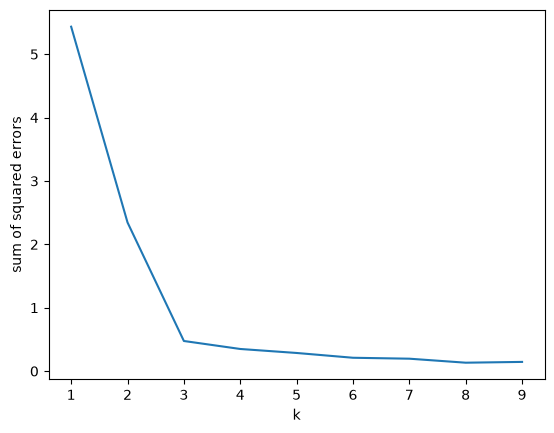

In [69]:
plt.xlabel('k')
plt.ylabel('sum of squared errors')
plt.plot(k_rng, sse)
plt.show()